In [402]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import sklearn
import shap
import os
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [403]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = Path(os.environ.get("DATA_DIR", PROJECT_ROOT / "data")).resolve()
GOLD_DIR = DATA_DIR / "gold"
# Analysis outputs
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHARTS_DIR = OUTPUT_DIR / "charts"
METRICS_DIR = OUTPUT_DIR / "metrics"

# Create output directories
for directory in [OUTPUT_DIR, CHARTS_DIR, METRICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: d:\Projects\remarcable-assignment
Data directory: D:\Projects\remarcable-assignment\data


In [404]:
dim_customer = pd.read_csv(
    GOLD_DIR / "dim_customer.csv"
)

dim_item = pd.read_csv(
    GOLD_DIR / "dim_item.csv"
)

dim_vendor = pd.read_csv(
    GOLD_DIR / "dim_vendor.csv"
)

fct_purchase_order_line = pd.read_csv(
    GOLD_DIR / "fct_purchase_order_line.csv"
)

item_purchase_history = pd.read_csv(
    GOLD_DIR / "item_purchase_history.csv"
)

validated_purchase_order_lines = pd.read_csv(
    GOLD_DIR / "fct_purchase_order_line_validated.csv"
)

In [405]:
# Filter validated purchase order lines for Company A and summarise dataset coverage
COMPANY_A = "CUST-A"
company_a = validated_purchase_order_lines[validated_purchase_order_lines["customer_id"] == COMPANY_A].copy()

print("Company A purchase lines:", len(company_a))
print("Unique purchase orders:", company_a["po_number"].nunique())
print("Unique items:", company_a["item_id"].nunique())
print("Unique vendors:", company_a["vendor_id"].nunique())

Company A purchase lines: 2315
Unique purchase orders: 820
Unique items: 122
Unique vendors: 12


In [406]:
company_a_active = company_a[
    company_a["status"].isin(["Received", "Closed", "Open"])
].copy()

display(company_a_active)

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount
0,PO-100000,CUST-A,VEND-06,2024-04-01,Closed,ITM-0431,10,0.72,7.20
9,PO-100003,CUST-A,VEND-09,2024-06-28,Closed,ITM-0201,24,3.80,91.20
10,PO-100003,CUST-A,VEND-09,2024-06-28,Closed,ITM-0442,1,18.89,18.89
14,PO-100005,CUST-A,VEND-08,2024-04-18,Closed,ITM-0614,6,4.91,29.46
22,PO-100009,CUST-A,VEND-12,2024-05-29,Closed,ITM-0612,1,3.97,3.97
...,...,...,...,...,...,...,...,...,...
8419,PO-103167,CUST-A,VEND-01,2025-10-16,Closed,ITM-0611,50,3.06,153.00
8420,PO-103167,CUST-A,VEND-01,2025-10-16,Closed,ITM-1006,1,1.32,1.32
8425,PO-103169,CUST-A,VEND-01,2026-04-03,Received,ITM-0623,3,2.56,7.68
8426,PO-103169,CUST-A,VEND-01,2026-04-03,Received,ITM-0627,10,7.37,73.70


In [407]:
# Separate active Company A purchase lines into priced and unpriced records
company_a_active = company_a[company_a["status"].isin(["Received", "Closed", "Open"])].copy()

company_a_priced = company_a_active[company_a_active["unit_price_paid"].notna()].copy()
company_a_unpriced = company_a_active[company_a_active["unit_price_paid"].isna()].copy()

print("Active purchase lines:", len(company_a_active))
print("Priced lines:", len(company_a_priced))
print("Unpriced lines:", len(company_a_unpriced))

Active purchase lines: 2186
Priced lines: 2178
Unpriced lines: 8


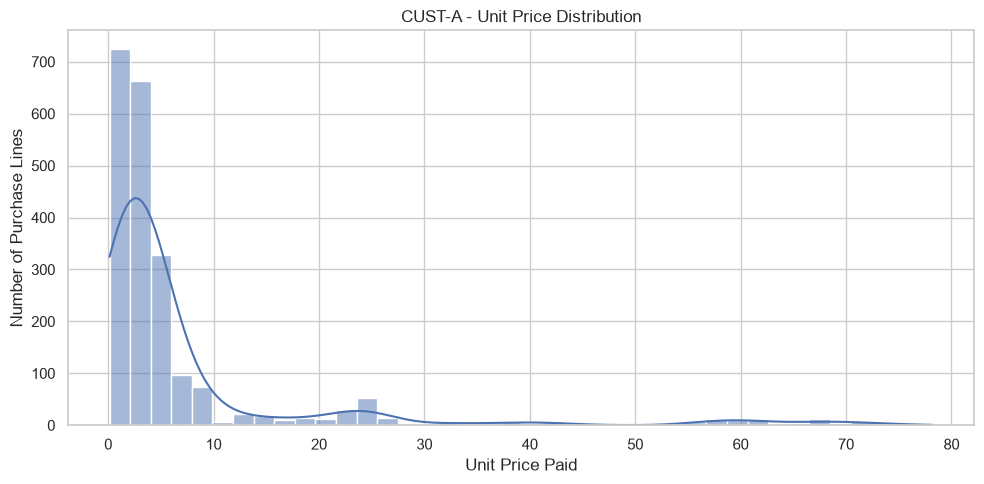

In [408]:
# Visualize and save the historical unit price distribution for Company A
plt.figure(figsize=(10, 5))
sns.histplot(data=company_a_priced, x="unit_price_paid", bins=40, kde=True)
plt.title("CUST-A - Unit Price Distribution")
plt.xlabel("Unit Price Paid")
plt.ylabel("Number of Purchase Lines")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "company_a_price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [409]:
# Engineer historical pricing, transaction history and calendar features for Company A price prediction
model_data = company_a_priced.copy()
model_data["order_date"] = pd.to_datetime(model_data["order_date"])
model_data = model_data.sort_values(["item_id", "order_date", "po_number"]).copy()

model_data["year"] = model_data["order_date"].dt.year
model_data["month"] = model_data["order_date"].dt.month
model_data["quarter"] = model_data["order_date"].dt.quarter

# Create historical features using previous transactions only
item_vendor = model_data.groupby(["item_id", "vendor_id"])["unit_price_paid"]
item_history = model_data.groupby("item_id")["unit_price_paid"]

model_data["previous_paid_price"] = item_vendor.shift(1)
model_data["previous_3_order_avg"] = item_vendor.transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
model_data["previous_3_order_median"] = item_vendor.transform(lambda x: x.shift(1).rolling(3, min_periods=1).median())

model_data["historical_item_avg"] = item_history.transform(lambda x: x.shift(1).expanding().mean())
model_data["historical_item_median"] = item_history.transform(lambda x: x.shift(1).expanding().median())
model_data["historical_item_count"] = item_history.transform(lambda x: x.shift(1).expanding().count())

model_data["historical_vendor_item_avg"] = item_vendor.transform(lambda x: x.shift(1).expanding().mean())
model_data["historical_vendor_item_median"] = item_vendor.transform(lambda x: x.shift(1).expanding().median())
model_data["historical_vendor_item_count"] = item_vendor.transform(lambda x: x.shift(1).expanding().count())

model_data["has_previous_vendor_item_history"] = model_data["historical_vendor_item_avg"].notna().astype(int)

# Inspect engineered features and missing values
engineered_features = [
    "previous_paid_price", "previous_3_order_avg", "previous_3_order_median",
    "historical_item_avg", "historical_item_median", "historical_item_count",
    "historical_vendor_item_avg", "historical_vendor_item_median",
    "historical_vendor_item_count", "has_previous_vendor_item_history"
]

display(model_data.head(15))
display(model_data[engineered_features].isna().sum())

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount,year,month,quarter,previous_paid_price,previous_3_order_avg,previous_3_order_median,historical_item_avg,historical_item_median,historical_item_count,historical_vendor_item_avg,historical_vendor_item_median,historical_vendor_item_count,has_previous_vendor_item_history
2889,PO-101076,CUST-A,VEND-06,2024-07-21,Received,ITM-0104,6,66.72,400.32,2024,7,3,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0
2854,PO-101063,CUST-A,VEND-03,2024-11-26,Received,ITM-0104,1,60.43,60.43,2024,11,4,NaN,NaN,NaN,66.72,66.72,1.00,NaN,NaN,0.00,0
8060,PO-103039,CUST-A,VEND-07,2024-12-06,Received,ITM-0104,4,62.29,249.16,2024,12,4,NaN,NaN,NaN,63.58,63.58,2.00,NaN,NaN,0.00,0
1601,PO-100592,CUST-A,VEND-06,2025-04-06,Closed,ITM-0104,4,65.73,262.92,2025,4,2,66.72,66.72,66.72,63.15,62.29,3.00,66.72,66.72,1.00,1
6598,PO-102500,CUST-A,VEND-11,2025-04-29,Received,ITM-0104,12,67.30,807.60,2025,4,2,NaN,NaN,NaN,63.79,64.01,4.00,NaN,NaN,0.00,0
946,PO-100344,CUST-A,VEND-06,2025-09-11,Closed,ITM-0104,10,65.78,657.80,2025,9,3,65.73,66.22,66.22,64.49,65.73,5.00,66.22,66.22,2.00,1
7854,PO-102967,CUST-A,VEND-07,2025-09-15,Received,ITM-0104,4,68.76,275.04,2025,9,3,62.29,62.29,62.29,64.71,65.75,6.00,62.29,62.29,1.00,1
4243,PO-101608,CUST-A,VEND-06,2026-01-03,Closed,ITM-0104,50,56.97,"2,848.50",2026,1,1,65.78,66.08,65.78,65.29,65.78,7.00,66.08,65.78,3.00,1
7790,PO-102947,CUST-A,VEND-06,2026-01-31,Closed,ITM-0104,24,60.42,"1,450.08",2026,1,1,56.97,62.83,65.73,64.25,65.75,8.00,63.80,65.75,4.00,1
4625,PO-101751,CUST-A,VEND-06,2026-02-02,Received,ITM-0104,50,56.39,"2,819.50",2026,2,1,60.42,61.06,60.42,63.82,65.73,9.00,63.12,65.73,5.00,1


previous_paid_price                 345
previous_3_order_avg                345
previous_3_order_median             345
historical_item_avg                 122
historical_item_median              122
historical_item_count                 0
historical_vendor_item_avg          345
historical_vendor_item_median       345
historical_vendor_item_count          0
has_previous_vendor_item_history      0
dtype: int64

In [410]:
# Analyse historical purchasing relationships and pricing coverage for each item-vendor combination
item_vendor_history = (
    company_a_priced.assign(order_date=pd.to_datetime(company_a_priced["order_date"]))
    .groupby(["item_id", "vendor_id"])
    .agg(transactions=("unit_price_paid", "count"),
         first_purchase=("order_date", "min"),
         last_purchase=("order_date", "max"),
         average_price=("unit_price_paid", "mean"))
    .reset_index()
)

item_vendor_history["history_months"] = (
    (item_vendor_history["last_purchase"].dt.year - item_vendor_history["first_purchase"].dt.year) * 12
    + item_vendor_history["last_purchase"].dt.month - item_vendor_history["first_purchase"].dt.month
)

display(item_vendor_history.sort_values("transactions", ascending=False).head(20))

,item_id,vendor_id,transactions,first_purchase,last_purchase,average_price,history_months
131,ITM-0433,VEND-09,51,2024-01-13,2026-08-23,1.22,31
181,ITM-0612,VEND-07,47,2024-01-03,2026-08-12,4.05,31
37,ITM-0237,VEND-02,46,2024-03-18,2026-08-09,3.16,29
182,ITM-0612,VEND-12,46,2024-01-05,2026-09-01,4.01,32
38,ITM-0237,VEND-04,39,2024-01-10,2026-08-25,3.02,31
331,ITM-1015,VEND-11,31,2024-01-03,2026-08-20,4.23,31
129,ITM-0433,VEND-01,29,2024-01-11,2026-08-07,1.17,31
116,ITM-0426,VEND-01,29,2024-01-12,2026-08-07,24.00,31
180,ITM-0612,VEND-05,29,2024-04-04,2026-08-23,3.79,28
7,ITM-0201,VEND-09,28,2024-02-19,2026-08-23,4.10,30


In [411]:
# Measure missing historical pricing features and their percentage of purchase records
history_missing = (
    model_data[["previous_paid_price", "previous_3_order_avg",
                "historical_item_avg", "historical_vendor_item_avg"]]
    .isna()
    .sum()
    .to_frame("missing_count")
)

history_missing["missing_pct"] = history_missing["missing_count"] / len(model_data) * 100

display(history_missing.round(2))

,missing_count,missing_pct
previous_paid_price,345,15.84
previous_3_order_avg,345,15.84
historical_item_avg,122,5.60
historical_vendor_item_avg,345,15.84


In [412]:
# Analyse missing previous-price history by vendor to assess historical pricing coverage
missing_history_by_vendor = (
    model_data.groupby("vendor_id")
    .agg(transactions=("unit_price_paid", "count"),
         missing_previous_price=("previous_paid_price", lambda x: x.isna().sum()))
    .reset_index()
)

missing_history_by_vendor["missing_pct"] = (
    missing_history_by_vendor["missing_previous_price"] /
    missing_history_by_vendor["transactions"] * 100
)

display(missing_history_by_vendor.sort_values("missing_pct", ascending=False).round(2))

,vendor_id,transactions,missing_previous_price,missing_pct
5,VEND-06,152,33,21.71
4,VEND-05,159,34,21.38
10,VEND-11,149,31,20.81
1,VEND-02,184,33,17.93
3,VEND-04,153,27,17.65
6,VEND-07,198,32,16.16
7,VEND-08,181,29,16.02
0,VEND-01,172,27,15.70
2,VEND-03,192,29,15.10
8,VEND-09,228,28,12.28


In [413]:
# Analyse vendor pricing history, average prices and availability of historical item-vendor information
vendor_history_analysis = (
    model_data.groupby("vendor_id")
    .agg(transactions=("unit_price_paid", "count"),
         average_price=("unit_price_paid", "mean"),
         missing_history=("historical_vendor_item_avg", lambda x: x.isna().sum()),
         average_price_with_history=("historical_vendor_item_avg", lambda x: x.notna().mean()))
    .reset_index()
)

vendor_history_analysis["missing_history_pct"] = (
    vendor_history_analysis["missing_history"] /
    vendor_history_analysis["transactions"] * 100
)

display(vendor_history_analysis.sort_values("missing_history_pct", ascending=False).round(2))


,vendor_id,transactions,average_price,missing_history,average_price_with_history,missing_history_pct
5,VEND-06,152,8.68,33,0.78,21.71
4,VEND-05,159,5.35,34,0.79,21.38
10,VEND-11,149,9.05,31,0.79,20.81
1,VEND-02,184,3.78,33,0.82,17.93
3,VEND-04,153,5.29,27,0.82,17.65
6,VEND-07,198,12.55,32,0.84,16.16
7,VEND-08,181,7.34,29,0.84,16.02
0,VEND-01,172,7.24,27,0.84,15.70
2,VEND-03,192,4.50,29,0.85,15.10
8,VEND-09,228,6.99,28,0.88,12.28


In [414]:
display(model_data)

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount,year,month,quarter,previous_paid_price,previous_3_order_avg,previous_3_order_median,historical_item_avg,historical_item_median,historical_item_count,historical_vendor_item_avg,historical_vendor_item_median,historical_vendor_item_count,has_previous_vendor_item_history
2889,PO-101076,CUST-A,VEND-06,2024-07-21,Received,ITM-0104,6,66.72,400.32,2024,7,3,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0
2854,PO-101063,CUST-A,VEND-03,2024-11-26,Received,ITM-0104,1,60.43,60.43,2024,11,4,NaN,NaN,NaN,66.72,66.72,1.00,NaN,NaN,0.00,0
8060,PO-103039,CUST-A,VEND-07,2024-12-06,Received,ITM-0104,4,62.29,249.16,2024,12,4,NaN,NaN,NaN,63.58,63.58,2.00,NaN,NaN,0.00,0
1601,PO-100592,CUST-A,VEND-06,2025-04-06,Closed,ITM-0104,4,65.73,262.92,2025,4,2,66.72,66.72,66.72,63.15,62.29,3.00,66.72,66.72,1.00,1
6598,PO-102500,CUST-A,VEND-11,2025-04-29,Received,ITM-0104,12,67.30,807.60,2025,4,2,NaN,NaN,NaN,63.79,64.01,4.00,NaN,NaN,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,PO-100193,CUST-A,VEND-09,2026-06-12,Open,ITM-1021,4,4.54,18.16,2026,6,2,4.83,4.64,4.56,4.56,4.55,4.00,4.64,4.56,3.00,1
7307,PO-102756,CUST-A,VEND-09,2026-07-10,Open,ITM-1021,4,4.91,19.64,2026,7,3,4.54,4.64,4.56,4.56,4.54,5.00,4.62,4.55,4.00,1
260,PO-100101,CUST-A,VEND-11,2024-09-16,Received,ITM-1022,24,4.67,112.08,2024,9,3,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0
7906,PO-102982,CUST-A,VEND-11,2026-03-29,Closed,ITM-1022,6,5.36,32.16,2026,3,1,4.67,4.67,4.67,4.67,4.67,1.00,4.67,4.67,1.00,1


In [415]:
# Define model features and target for Company A price prediction

FEATURES = [
    "item_id",
    "vendor_id",
    "quantity_ordered",
    "year",
    "month",
    "quarter",

    # Previous price features
    "previous_paid_price",
    "previous_3_order_avg",
    "previous_3_order_median",

    # Historical item pricing
    "historical_item_avg",
    "historical_item_median",
    "historical_item_count",

    # Historical vendor-item pricing
    "historical_vendor_item_avg",
    "historical_vendor_item_median",
    "historical_vendor_item_count",

    # History indicator
    "has_previous_vendor_item_history"
]

TARGET = "unit_price_paid"

# Validate that all model columns exist
required_columns = FEATURES + [TARGET]
missing_columns = [col for col in required_columns if col not in model_data.columns]

if missing_columns:
    raise ValueError(f"Missing required model columns: {missing_columns}")

print("Number of features:", len(FEATURES))
print("Target variable:", TARGET)
print("All required columns are available.")

Number of features: 16
Target variable: unit_price_paid
All required columns are available.


In [416]:
# Prepare modelling dataset and validate feature types

# Convert purchase dates
model_data["order_date"] = pd.to_datetime(
    model_data["order_date"],
    errors="coerce"
)

# Remove records without valid dates
model_data = model_data.dropna(subset=["order_date"]).copy()

# Sort chronologically
model_data = model_data.sort_values(
    ["order_date", "po_number", "item_id"]
).reset_index(drop=True)

# Numerical features
numeric_features = [
    "quantity_ordered",
    "year",
    "month",
    "quarter",
    "previous_paid_price",
    "previous_3_order_avg",
    "previous_3_order_median",
    "historical_item_avg",
    "historical_item_median",
    "historical_item_count",
    "historical_vendor_item_avg",
    "historical_vendor_item_median",
    "historical_vendor_item_count",
    "has_previous_vendor_item_history"
]

# Categorical features
categorical_features = [
    "item_id",
    "vendor_id"
]

# Combine model features
FEATURES = numeric_features + categorical_features

# Convert numerical features
model_data[numeric_features] = (
    model_data[numeric_features]
    .apply(pd.to_numeric, errors="coerce")
)

# Convert target variable
model_data[TARGET] = pd.to_numeric(
    model_data[TARGET],
    errors="coerce"
)

# Remove records without valid target prices
model_data = model_data.dropna(
    subset=[TARGET]
).copy()

# Ensure categorical identifiers are treated as categories
model_data[categorical_features] = (
    model_data[categorical_features].astype("category")
)

# Validate required modelling columns
missing_columns = [
    col for col in FEATURES + [TARGET]
    if col not in model_data.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Dataset summary
print("Modelling records:", len(model_data))
print("Unique purchase orders:", model_data["po_number"].nunique())
print("Unique items:", model_data["item_id"].nunique())
print("Unique vendors:", model_data["vendor_id"].nunique())
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

display(model_data[FEATURES + [TARGET]].head())

Modelling records: 2178
Unique purchase orders: 768
Unique items: 122
Unique vendors: 12
Numerical features: 14
Categorical features: 2


,quantity_ordered,year,month,quarter,previous_paid_price,previous_3_order_avg,previous_3_order_median,historical_item_avg,historical_item_median,historical_item_count,historical_vendor_item_avg,historical_vendor_item_median,historical_vendor_item_count,has_previous_vendor_item_history,item_id,vendor_id,unit_price_paid
0,6,2024,1,1,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0,ITM-0434,VEND-10,1.39
1,6,2024,1,1,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0,ITM-0201,VEND-08,4.09
2,4,2024,1,1,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0,ITM-0219,VEND-08,1.69
3,12,2024,1,1,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0,ITM-0903,VEND-08,0.20
4,1,2024,1,1,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,0.00,0,ITM-0623,VEND-01,2.40


In [417]:
print(
    "Zero or negative prices:",
    (model_data[TARGET] <= 0).sum()
)

Zero or negative prices: 0


In [418]:
# Split Company A modelling data chronologically (80% training, 20% testing)

split_date = model_data["order_date"].quantile(0.80)

train_data = model_data[
    model_data["order_date"] < split_date
].copy()

test_data = model_data[
    model_data["order_date"] >= split_date
].copy()

# Validate chronological separation
if not train_data.empty and not test_data.empty:
    assert train_data["order_date"].max() < test_data["order_date"].min()

# Display split information
print("Split date:", split_date)

print("\nTraining records:", len(train_data))
print("Testing records:", len(test_data))

print(
    "\nTraining period:",
    train_data["order_date"].min(),
    "to",
    train_data["order_date"].max()
)

print(
    "\nTesting period:",
    test_data["order_date"].min(),
    "to",
    test_data["order_date"].max()
)

print(
    "\nTraining percentage:",
    round(len(train_data) / len(model_data) * 100, 2), "%"
)

print(
    "Testing percentage:",
    round(len(test_data) / len(model_data) * 100, 2), "%"
)

Split date: 2026-02-18 00:00:00

Training records: 1741
Testing records: 437

Training period: 2024-01-01 00:00:00 to 2026-02-17 00:00:00

Testing period: 2026-02-18 00:00:00 to 2026-09-01 00:00:00

Training percentage: 79.94 %
Testing percentage: 20.06 %


In [419]:
assert train_data['order_date'].max() < test_data['order_date'].min()

print("Chronological split validated.")

Chronological split validated.


In [420]:
# Prepare training and testing features and target variables

# Training dataset
X_train = train_data[FEATURES].copy()
y_train = train_data[TARGET].copy()

# Testing dataset
X_test = test_data[FEATURES].copy()
y_test = test_data[TARGET].copy()

# Validate dataset dimensions
assert X_train.shape[1] == len(FEATURES)
assert X_test.shape[1] == len(FEATURES)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

# Display dataset dimensions
print("Training features (X_train):", X_train.shape)
print("Testing features (X_test):", X_test.shape)

print("Training target (y_train):", y_train.shape)
print("Testing target (y_test):", y_test.shape)

print("\nFeature columns consistent:", list(X_train.columns) == list(X_test.columns))

Training features (X_train): (1741, 16)
Testing features (X_test): (437, 16)
Training target (y_train): (1741,)
Testing target (y_test): (437,)

Feature columns consistent: True


In [421]:
# Define preprocessing pipelines for numerical and categorical features

# Numerical feature preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical feature preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline configured.")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline configured.
Numerical features: 14
Categorical features: 2


In [422]:
# Define regression models for Company A price prediction

# Ridge Regression
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

# Random Forest Regression
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost Regression
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# Collect models for evaluation
models = {
    "Ridge Regression": ridge_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

print("Models configured:", list(models.keys()))

Models configured: ['Ridge Regression', 'Random Forest', 'XGBoost']


In [423]:
# Train all regression models using Company A historical purchase data
models = {"Ridge": ridge_model, "Random Forest": rf_model, "XGBoost": xgb_model}
trained_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully.")
print("\nAll models trained successfully.")

Training Ridge...
Ridge trained successfully.
Training Random Forest...
Random Forest trained successfully.
Training XGBoost...
XGBoost trained successfully.

All models trained successfully.


In [424]:
# Generate baseline and machine learning predictions for Company A
baseline_predictions = (
    test_data['historical_vendor_item_avg'].copy()
)

# Fallback 1: Historical item average
baseline_predictions = baseline_predictions.fillna(
    test_data['historical_item_avg']
)

# Fallback 2: Training median
training_median = y_train.median()

baseline_predictions = baseline_predictions.fillna(
    training_median
)

#Predictions for all the models
# Generate baseline and machine learning predictions for Company A
predictions = {
    "Baseline": baseline_predictions,
    "Ridge": pd.Series(ridge_model.predict(X_test), index=X_test.index),
    "Random Forest": pd.Series(rf_model.predict(X_test), index=X_test.index),
    "XGBoost": pd.Series(xgb_model.predict(X_test), index=X_test.index)
}

In [425]:
def evaluate_model(y_actual, y_pred):

    y_actual = np.asarray(y_actual)
    y_pred = np.asarray(y_pred)

    absolute_errors = np.abs(y_actual - y_pred)

    return {
        'MAE': mean_absolute_error(y_actual, y_pred),

        'RMSE': np.sqrt(
            mean_squared_error(y_actual, y_pred)
        ),

        'MAPE (%)': np.mean(
            np.abs((y_actual - y_pred) / y_actual)
        ) * 100,

        'R2': r2_score(y_actual, y_pred),

        'Median AE': median_absolute_error(
            y_actual, y_pred
        ),

        'WAPE (%)': (
            absolute_errors.sum() /
            np.abs(y_actual).sum()
        ) * 100,

        'Bias': np.mean(y_pred - y_actual)
    }

In [426]:
results = {}

for name, prediction in predictions.items():

    results[name] = evaluate_model(
        y_test,
        prediction
    )

evaluation_results = pd.DataFrame(results).T

display(
    evaluation_results.round(4)
)

,MAE,RMSE,MAPE (%),R2,Median AE,WAPE (%),Bias
Baseline,0.45,2.21,6.41,0.97,0.13,6.29,-0.36
Ridge,0.74,2.25,28.30,0.96,0.43,10.36,-0.17
Random Forest,0.41,2.17,5.89,0.97,0.09,5.75,-0.21
XGBoost,0.60,2.22,13.13,0.97,0.21,8.48,-0.01


In [427]:
missing_summary = pd.DataFrame({
    'missing_count': train_data[FEATURES].isna().sum(),
    'missing_pct': (
        train_data[FEATURES].isna().mean() * 100
    )
})

display(
    missing_summary.sort_values(
        'missing_pct',
        ascending=False
    ).round(2)
)

,missing_count,missing_pct
previous_3_order_avg,320,18.38
previous_3_order_median,320,18.38
previous_paid_price,320,18.38
historical_vendor_item_median,320,18.38
historical_vendor_item_avg,320,18.38
historical_item_median,119,6.84
historical_item_avg,119,6.84
quarter,0,0.00
quantity_ordered,0,0.00
year,0,0.00


In [428]:
# Analyse Random Forest prediction accuracy by item
test_aligned = test_data.loc[X_test.index].copy()

item_diagnostics = test_aligned[
    ['item_id', 'unit_price_paid']
].copy()

item_diagnostics['prediction'] = predictions['Random Forest']

item_diagnostics['absolute_error'] = (
    item_diagnostics['unit_price_paid'] -
    item_diagnostics['prediction']
).abs()

item_summary = (
    item_diagnostics.groupby('item_id')
    .agg(
        Transactions=('unit_price_paid', 'count'),
        Actual_Avg=('unit_price_paid', 'mean'),
        Predicted_Avg=('prediction', 'mean'),
        MAE=('absolute_error', 'mean'),
        Max_Error=('absolute_error', 'max')
    )
    .sort_values('MAE', ascending=False)
)

display(item_summary.head(20))


,Transactions,Actual_Avg,Predicted_Avg,MAE,Max_Error
item_id,,,,,
ITM-0902,4,14.97,4.49,10.68,42.29
ITM-0721,2,36.64,32.32,4.32,5.91
ITM-0715,2,71.07,69.73,4.28,5.61
ITM-1017,1,3.02,6.20,3.18,3.18
ITM-0947,1,0.43,3.37,2.94,2.94
ITM-0250,9,61.25,59.42,2.31,5.67
ITM-0733,1,22.01,20.06,1.95,1.95
ITM-0943,3,24.42,23.60,1.75,3.47
ITM-0517,3,41.80,40.05,1.75,2.32


### Top 10 Items by Count

In [429]:
# Identify Company A's top 10 items by total purchased quantity
top10_quantity = (
    company_a_priced.groupby("item_id")
    .agg(total_quantity=("quantity_ordered", "sum"), 
         total_purchase_value=("extended_amount", "sum"), 
         purchase_lines=("item_id", "count"), 
         average_unit_price=("unit_price_paid", "mean"))
    .sort_values("total_quantity", ascending=False)
    .head(10)
    .reset_index()
)
display(top10_quantity)

,item_id,total_quantity,total_purchase_value,purchase_lines,average_unit_price
0,ITM-0612,997,"3,885.78",122,3.97
1,ITM-0433,891,"1,018.17",120,1.17
2,ITM-0201,801,"3,174.94",82,4.10
3,ITM-1015,799,"3,281.34",99,4.20
4,ITM-0426,623,"14,505.37",67,24.03
5,ITM-0434,546,772.40,57,1.44
6,ITM-0237,525,"1,615.93",85,3.10
7,ITM-0621,480,"1,876.87",56,3.95
8,ITM-0306,440,405.96,67,0.94
9,ITM-0311,437,"2,827.29",52,6.70


In [430]:
# Identify Company A's top 10 items by total purchase value
top10_purchase = (
    company_a_priced
    .groupby('item_id')
    .agg(
        total_quantity=('quantity_ordered', 'sum'),
        total_purchase_value=('extended_amount', 'sum'),
        purchase_lines=('item_id', 'count'),
        average_unit_price=('unit_price_paid', 'mean')
    )
    .sort_values('total_purchase_value', ascending=False)
    .head(10)
    .reset_index()
)

display(top10_purchase)

,item_id,total_quantity,total_purchase_value,purchase_lines,average_unit_price
0,ITM-0426,623,"14,505.37",67,24.03
1,ITM-0737,200,"13,682.99",20,70.19
2,ITM-0250,196,"11,617.95",38,59.38
3,ITM-0104,171,"10,217.21",11,63.19
4,ITM-0517,144,"5,677.68",18,40.12
5,ITM-0612,997,"3,885.78",122,3.97
6,ITM-1015,799,"3,281.34",99,4.20
7,ITM-0201,801,"3,174.94",82,4.10
8,ITM-0311,437,"2,827.29",52,6.70
9,ITM-0715,38,"2,631.32",9,69.62


In [431]:
# Get top 10 item IDs
top10_item_ids = top10_quantity['item_id'].tolist()

# Filter original test data
top10_test = test_data[
    test_data['item_id'].isin(top10_item_ids)
].copy()

print("Top 10 test records:", len(top10_test))
print("Unique items:", top10_test['item_id'].nunique())

display(
    top10_test[
        ['order_date', 'item_id', 'vendor_id',
         'quantity_ordered', 'unit_price_paid']
    ].head()
)

Top 10 test records: 164
Unique items: 10


,order_date,item_id,vendor_id,quantity_ordered,unit_price_paid
1741,2026-02-18,ITM-0433,VEND-09,6,1.25
1743,2026-02-18,ITM-0201,VEND-09,1,4.34
1746,2026-02-18,ITM-0433,VEND-09,10,1.20
1750,2026-02-20,ITM-0237,VEND-02,2,3.32
1751,2026-02-20,ITM-0621,VEND-02,24,4.23


In [432]:
# Features for top 10 test records
X_top10 = top10_test[FEATURES]

# Actual prices
y_top10 = top10_test['unit_price_paid']

# Baseline
baseline_top10 = (
    top10_test['historical_vendor_item_avg'].copy()
)

baseline_top10 = baseline_top10.fillna(
    top10_test['historical_item_avg']
)

baseline_top10 = baseline_top10.fillna(
    training_median
)

# Existing trained model predictions
top10_predictions = {
    'Baseline': baseline_top10,
    'Ridge': ridge_model.predict(X_top10),
    'Random Forest': rf_model.predict(X_top10),
    'XGBoost': xgb_model.predict(X_top10)
}

In [433]:
# Evaluate all four models on top 10 items

top10_results = {}

for name, prediction in top10_predictions.items():

    top10_results[name] = evaluate_model(
        y_top10,
        prediction
    )

top10_evaluation = pd.DataFrame(
    top10_results
).T

display(top10_evaluation.round(4))

,MAE,RMSE,MAPE (%),R2,Median AE,WAPE (%),Bias
Baseline,0.25,0.46,4.36,0.99,0.13,4.60,-0.22
Ridge,0.46,0.58,15.66,0.99,0.38,8.41,-0.14
Random Forest,0.19,0.37,3.21,1.00,0.08,3.50,-0.04
XGBoost,0.31,0.44,7.30,1.00,0.19,5.71,0.01


In [434]:
# Overall test performance
overall_results = evaluation_results.copy()

# Combine overall and top 10 results
comparison = pd.concat(
    {
        'All Items': overall_results,
        'Top 10 Items': top10_evaluation
    },
    names=['Dataset', 'Model']
)

display(comparison.round(4))

MAE  RMSE  MAPE (%)   R2  Median AE  WAPE (%)  \
Dataset      Model                                                          
All Items    Baseline      0.45  2.21      6.41 0.97       0.13      6.29   
             Ridge         0.74  2.25     28.30 0.96       0.43     10.36   
             Random Forest 0.41  2.17      5.89 0.97       0.09      5.75   
             XGBoost       0.60  2.22     13.13 0.97       0.21      8.48   
Top 10 Items Baseline      0.25  0.46      4.36 0.99       0.13      4.60   
             Ridge         0.46  0.58     15.66 0.99       0.38      8.41   
             Random Forest 0.19  0.37      3.21 1.00       0.08      3.50   
             XGBoost       0.31  0.44      7.30 1.00       0.19      5.71   

                            Bias  
Dataset      Model                
All Items    Baseline      -0.36  
             Ridge         -0.17  
             Random Forest -0.21  
             XGBoost       -0.01  
Top 10 Items Baseline      -0.22  
             Ridge         -0.14  
             Random Forest -0.04  
             XGBoost        0.01

### Top 10 by purchase

In [435]:
# Filter testing records for Company A's top 10 highest-spend items
top10_purchase_ids = top10_purchase["item_id"].tolist()
top10_purchase_test = test_data[test_data["item_id"].isin(top10_purchase_ids)].copy()
print("Top 10 purchase test records:", len(top10_purchase_test))
print("Unique items:", top10_purchase_test["item_id"].nunique())
display(top10_purchase_test.head())

Top 10 purchase test records: 105
Unique items: 9


,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount,year,month,quarter,previous_paid_price,previous_3_order_avg,previous_3_order_median,historical_item_avg,historical_item_median,historical_item_count,historical_vendor_item_avg,historical_vendor_item_median,historical_vendor_item_count,has_previous_vendor_item_history
1743,PO-102958,CUST-A,VEND-09,2026-02-18,Closed,ITM-0201,1,4.34,4.34,2026,2,1,4.32,4.25,4.32,4.06,4.08,64.00,4.07,4.08,22.00,1
1752,PO-102020,CUST-A,VEND-06,2026-02-20,Closed,ITM-0311,2,6.88,13.76,2026,2,1,6.56,6.60,6.56,6.61,6.63,41.00,6.44,6.46,14.00,1
1754,PO-102020,CUST-A,VEND-06,2026-02-20,Closed,ITM-0715,2,67.21,134.42,2026,2,1,72.13,69.98,69.98,69.21,69.01,7.00,69.98,69.98,2.00,1
1756,PO-101173,CUST-A,VEND-07,2026-02-21,Received,ITM-0250,1,65.13,65.13,2026,2,1,60.21,57.25,56.30,58.80,58.69,29.00,57.59,57.75,7.00,1
1758,PO-101173,CUST-A,VEND-07,2026-02-21,Received,ITM-0612,2,3.98,7.96,2026,2,1,4.06,4.03,4.03,3.92,3.92,95.00,3.98,3.97,33.00,1


In [436]:
# Features for top 10 test records
X_top10_purchase = top10_purchase_test[FEATURES]

# Actual prices
y_top10_purchase = top10_purchase_test['unit_price_paid']

# Baseline
baseline_top10_purchase = (
    top10_purchase_test['historical_vendor_item_avg'].copy()
)

baseline_top10_purchase = baseline_top10_purchase.fillna(
    top10_purchase_test['historical_item_avg']
)

baseline_top10_purchase = baseline_top10_purchase.fillna(
    training_median
)

# Existing trained model predictions
top10_purchase_predictions = {
    'Baseline': baseline_top10_purchase,
    'Ridge': ridge_model.predict(X_top10_purchase),
    'Random Forest': rf_model.predict(X_top10_purchase),
    'XGBoost': xgb_model.predict(X_top10_purchase)
}

In [437]:
# Evaluate all four models on top 10 items

top10_purchase_results = {}

for name, prediction in top10_purchase_predictions.items():

    top10_purchase_results[name] = evaluate_model(
        y_top10_purchase,
        prediction
    )

top10_purchase_evaluation = pd.DataFrame(
    top10_purchase_results
).T

display(top10_purchase_evaluation.round(4))

,MAE,RMSE,MAPE (%),R2,Median AE,WAPE (%),Bias
Baseline,0.75,1.48,4.72,0.99,0.28,4.85,-0.62
Ridge,0.83,1.34,8.79,1.00,0.59,5.35,-0.37
Random Forest,0.59,1.19,3.46,1.00,0.17,3.80,-0.28
XGBoost,0.62,1.17,4.77,1.00,0.31,4.03,-0.28


In [438]:
# Overall test performance
overall_results = evaluation_results.copy()

# Combine overall and top 10 results
comparison = pd.concat(
    {
        'All Items': overall_results,
        'Top 10 Items': top10_evaluation,
        'Top 10 Purchase Value': top10_purchase_evaluation
    },
    names=['Dataset', 'Model']
)

display(comparison.round(4))

MAE  RMSE  MAPE (%)   R2  Median AE  \
Dataset               Model                                                
All Items             Baseline      0.45  2.21      6.41 0.97       0.13   
                      Ridge         0.74  2.25     28.30 0.96       0.43   
                      Random Forest 0.41  2.17      5.89 0.97       0.09   
                      XGBoost       0.60  2.22     13.13 0.97       0.21   
Top 10 Items          Baseline      0.25  0.46      4.36 0.99       0.13   
                      Ridge         0.46  0.58     15.66 0.99       0.38   
                      Random Forest 0.19  0.37      3.21 1.00       0.08   
                      XGBoost       0.31  0.44      7.30 1.00       0.19   
Top 10 Purchase Value Baseline      0.75  1.48      4.72 0.99       0.28   
                      Ridge         0.83  1.34      8.79 1.00       0.59   
                      Random Forest 0.59  1.19      3.46 1.00       0.17   
                      XGBoost       0.62  1.17      4.77 1.00       0.31   

                                     WAPE (%)  Bias  
Dataset               Model                          
All Items             Baseline           6.29 -0.36  
                      Ridge             10.36 -0.17  
                      Random Forest      5.75 -0.21  
                      XGBoost            8.48 -0.01  
Top 10 Items          Baseline           4.60 -0.22  
                      Ridge              8.41 -0.14  
                      Random Forest      3.50 -0.04  
                      XGBoost            5.71  0.01  
Top 10 Purchase Value Baseline           4.85 -0.62  
                      Ridge              5.35 -0.37  
                      Random Forest      3.80 -0.28  
                      XGBoost            4.03 -0.28

### SHAP Explanation

In [439]:
X_shap = X_test.copy()

print("SHAP evaluation records:", len(X_shap))
print("Features:", len(X_shap.columns))

SHAP evaluation records: 437
Features: 16


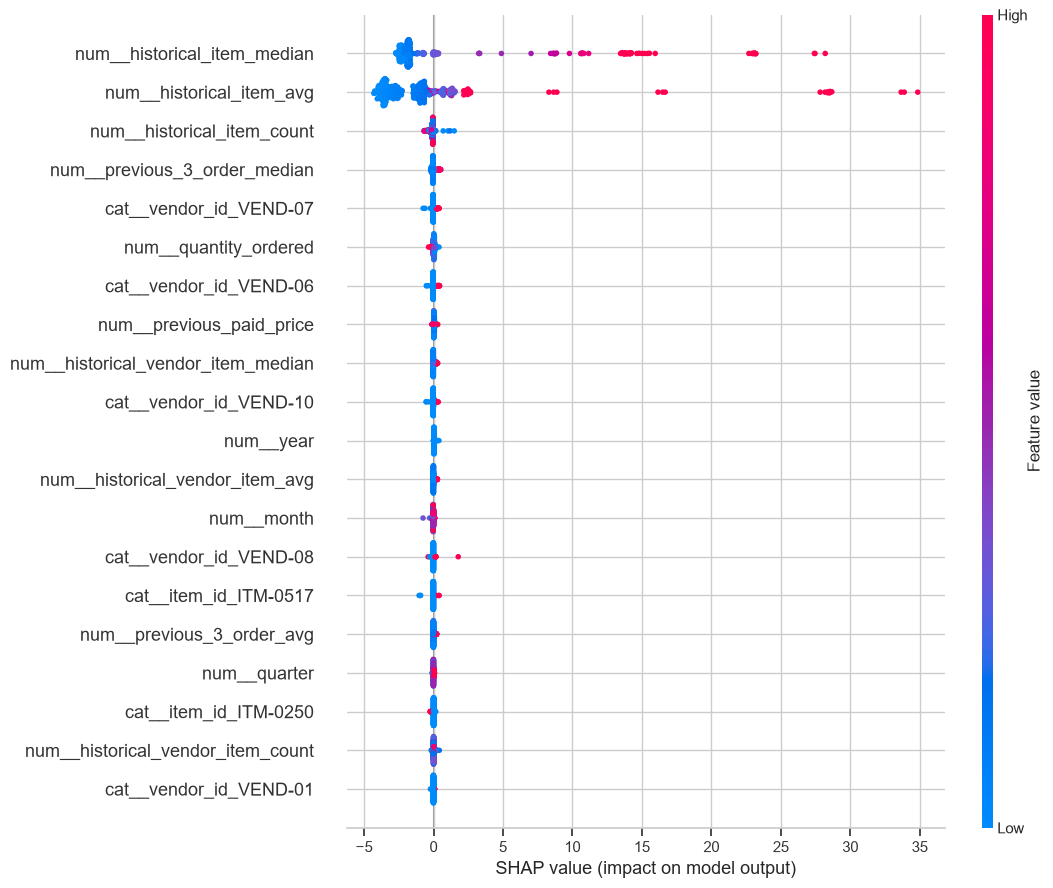

In [440]:
# Explain Random Forest price predictions using SHAP feature importance
rf_preprocessor = rf_model.named_steps['preprocessor']

X_rf_transformed = rf_preprocessor.transform(X_shap)

# Convert sparse matrix to dense numerical array
if hasattr(X_rf_transformed, "toarray"):
    X_rf_transformed = X_rf_transformed.toarray()

X_rf_transformed = X_rf_transformed.astype(np.float64)

# Feature names
rf_feature_names = rf_preprocessor.get_feature_names_out()

# SHAP explainer
rf_explainer = shap.TreeExplainer(
    rf_model.named_steps['model']
)

rf_shap_values = rf_explainer.shap_values(
    X_rf_transformed
)

plt.close("all")
shap.summary_plot(rf_shap_values, X_rf_transformed, feature_names=rf_feature_names, show=False)
fig = plt.gcf()
fig.set_size_inches(14, 9)
fig.savefig(CHARTS_DIR / "company_a_random_forest_shap_summary.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)

In [441]:
# Explain one Random Forest purchase order line using SHAP
po_index = X_test.index[0]
local_position = X_test.index.get_loc(po_index)
local_shap_values = rf_shap_values[local_position]
local_explanation = pd.DataFrame({"feature": rf_feature_names, "shap_value": local_shap_values})
local_explanation["absolute_shap"] = local_explanation["shap_value"].abs()
local_explanation = local_explanation.sort_values("absolute_shap", ascending=False).head(10)
print("Purchase order:", test_data.loc[po_index, "po_number"])
print("Item:", test_data.loc[po_index, "item_id"])
print("Actual unit price:", round(y_test.loc[po_index], 2))
print("Predicted unit price:", round(rf_model.predict(X_test.loc[[po_index]])[0], 2))
display(local_explanation)

Purchase order: PO-100330
Item: ITM-0433
Actual unit price: 1.25
Predicted unit price: 1.25


,feature,shap_value,absolute_shap
7,num__historical_item_avg,-3.48,3.48
8,num__historical_item_median,-2.28,2.28
9,num__historical_item_count,-0.04,0.04
6,num__previous_3_order_median,-0.04,0.04
138,cat__vendor_id_VEND-06,-0.03,0.03
139,cat__vendor_id_VEND-07,-0.03,0.03
142,cat__vendor_id_VEND-10,-0.03,0.03
1,num__year,0.02,0.02
0,num__quantity_ordered,0.02,0.02
4,num__previous_paid_price,0.02,0.02


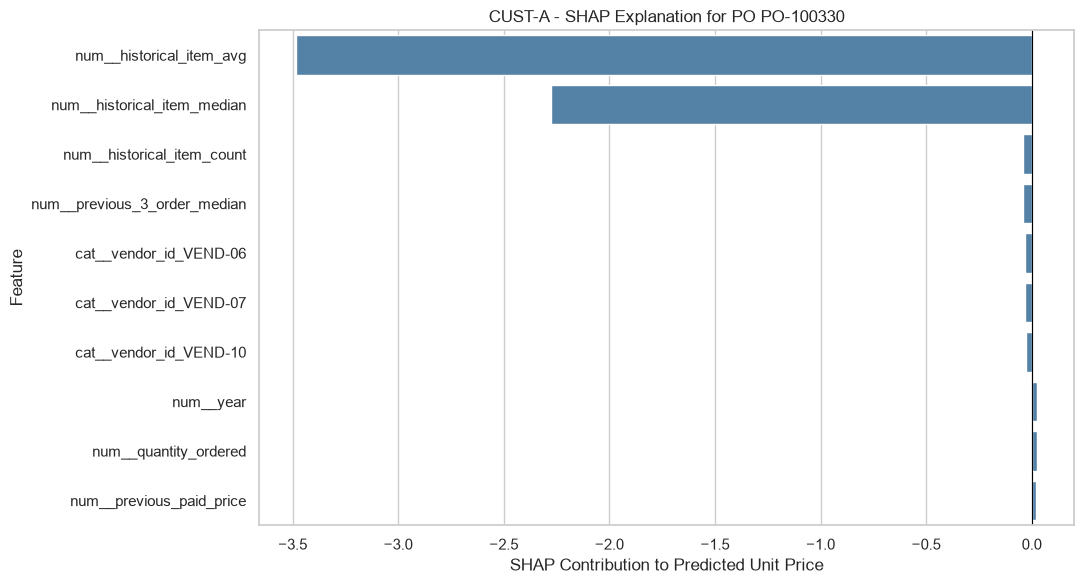

In [442]:
# Generate and save local SHAP explanation for one purchase order line
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=local_explanation, x="shap_value", y="feature", ax=ax, color="steelblue")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"CUST-A - SHAP Explanation for PO {test_data.loc[po_index, 'po_number']}")
ax.set_xlabel("SHAP Contribution to Predicted Unit Price")
ax.set_ylabel("Feature")
plt.tight_layout()
fig.savefig(CHARTS_DIR / "company_a_random_forest_shap_local.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

In [443]:
# Compare actual and predicted prices and identify largest Random Forest errors
diagnostics = test_data.loc[X_test.index, [
    'po_number',
    'order_date',
    'item_id',
    'vendor_id',
    'unit_price_paid'
]].copy()

for model_name, preds in predictions.items():

    diagnostics[f'{model_name}_prediction'] = preds

    diagnostics[f'{model_name}_error'] = (
        diagnostics['unit_price_paid'] - preds
    ).abs()

    diagnostics[f'{model_name}_percentage_error'] = (
        diagnostics[f'{model_name}_error'] /
        diagnostics['unit_price_paid'].abs()
    ) * 100

display(
    diagnostics.sort_values(
        'Random Forest_error',
        ascending=False
    ).head(20)
)

,po_number,order_date,item_id,vendor_id,unit_price_paid,Baseline_prediction,Baseline_error,Baseline_percentage_error,Ridge_prediction,Ridge_error,Ridge_percentage_error,Random Forest_prediction,Random Forest_error,Random Forest_percentage_error,XGBoost_prediction,XGBoost_error,XGBoost_percentage_error
2019,PO-101587,2026-07-01,ITM-0902,VEND-08,47.00,4.18,42.82,91.11,4.92,42.08,89.53,4.71,42.29,89.97,8.11,38.89,82.75
1979,PO-100193,2026-06-12,ITM-0721,VEND-09,38.85,35.86,2.99,7.70,33.11,5.74,14.76,32.94,5.91,15.22,45.90,7.05,18.15
2100,PO-102133,2026-08-01,ITM-0250,VEND-09,65.69,59.94,5.75,8.76,59.38,6.31,9.61,60.02,5.67,8.64,60.24,5.45,8.30
1810,PO-101521,2026-03-25,ITM-0715,VEND-07,74.93,68.90,6.03,8.05,69.52,5.41,7.22,69.32,5.61,7.49,69.94,4.99,6.66
1756,PO-101173,2026-02-21,ITM-0250,VEND-07,65.13,57.59,7.54,11.58,59.06,6.07,9.33,59.99,5.14,7.89,59.05,6.08,9.34
1863,PO-100681,2026-04-23,ITM-1018,VEND-08,4.57,3.10,1.47,32.17,4.86,0.29,6.45,8.08,3.51,76.87,4.22,0.35,7.63
1950,PO-101007,2026-06-02,ITM-0943,VEND-11,27.02,23.24,3.78,13.98,22.75,4.27,15.80,23.55,3.47,12.85,24.54,2.48,9.17
1767,PO-102980,2026-02-27,ITM-1017,VEND-05,3.02,3.10,0.08,2.65,5.30,2.28,75.42,6.20,3.18,105.14,5.42,2.40,79.52
1856,PO-102969,2026-04-16,ITM-0947,VEND-02,0.43,3.10,2.67,620.93,4.78,4.35,"1,012.48",3.37,2.94,683.91,3.48,3.05,709.07
1754,PO-102020,2026-02-20,ITM-0715,VEND-06,67.21,69.98,2.77,4.12,69.21,2.00,2.98,70.15,2.94,4.37,70.03,2.82,4.20


In [444]:
# Investigate a dynamically selected purchase line using available test records
problem_index = diagnostics["Random Forest_error"].idxmax()
problem_record = test_data.loc[[problem_index]]
diagnostic_columns = ["po_number", "order_date", "item_id", "vendor_id", "quantity_ordered", 
                      TARGET, "previous_paid_price", "previous_3_order_avg", "historical_item_avg", 
                      "historical_vendor_item_avg", "has_previous_vendor_item_history"]

display(problem_record[diagnostic_columns])

,po_number,order_date,item_id,vendor_id,quantity_ordered,unit_price_paid,previous_paid_price,previous_3_order_avg,historical_item_avg,historical_vendor_item_avg,has_previous_vendor_item_history
2019,PO-101587,2026-07-01,ITM-0902,VEND-08,2,47.00,4.38,4.17,7.57,4.18,1


In [445]:
# Examine historical purchase transactions for the selected item before its prediction date
problem_item = problem_record["item_id"].iloc[0]
problem_date = problem_record["order_date"].iloc[0]
item_history = model_data[(model_data["item_id"] == problem_item) & 
                          (model_data["order_date"] < problem_date)].sort_values(["order_date", "po_number"])

display(problem_item)
display(item_history[["order_date", "po_number", "vendor_id", "quantity_ordered", TARGET]])

'ITM-0902'

,order_date,po_number,vendor_id,quantity_ordered,unit_price_paid
97,2024-02-19,PO-100884,VEND-10,2,39.00
117,2024-02-24,PO-102964,VEND-08,4,4.20
167,2024-03-27,PO-100614,VEND-09,4,4.21
200,2024-04-15,PO-100843,VEND-10,1,3.99
254,2024-05-07,PO-101851,VEND-09,2,4.04
471,2024-07-31,PO-101275,VEND-08,1,4.11
530,2024-08-16,PO-101824,VEND-09,2,4.20
926,2025-03-08,PO-101229,VEND-08,4,4.02
968,2025-03-21,PO-102504,VEND-11,4,3.81
1063,2025-04-29,PO-100668,VEND-10,5,37.80


### Outlier Price Case

In [446]:
# Compare vendor pricing history and identify vendors without priced transactions
problem_item = problem_record["item_id"].iloc[0]
item_vendor_analysis = (
    model_data[model_data["item_id"] == problem_item]
    .groupby("vendor_id")
    .agg(Transaction_Count=("unit_price_paid", "count"), 
         Average_Price=("unit_price_paid", "mean"), 
         Minimum_Price=("unit_price_paid", "min"), 
         Maximum_Price=("unit_price_paid", "max"), 
         Median_Price=("unit_price_paid", "median"))
    .reset_index()
)
item_vendor_analysis["Pricing_History"] = np.where(item_vendor_analysis["Transaction_Count"] > 0, "Available", "No priced transactions")

display(item_vendor_analysis.round(2))

,vendor_id,Transaction_Count,Average_Price,Minimum_Price,Maximum_Price,Median_Price,Pricing_History
0,VEND-01,0,NaN,NaN,NaN,NaN,No priced transactions
1,VEND-02,0,NaN,NaN,NaN,NaN,No priced transactions
2,VEND-03,0,NaN,NaN,NaN,NaN,No priced transactions
3,VEND-04,0,NaN,NaN,NaN,NaN,No priced transactions
4,VEND-05,0,NaN,NaN,NaN,NaN,No priced transactions
5,VEND-06,0,NaN,NaN,NaN,NaN,No priced transactions
6,VEND-07,0,NaN,NaN,NaN,NaN,No priced transactions
7,VEND-08,5,12.74,4.02,47.00,4.20,Available
8,VEND-09,6,4.22,4.04,4.43,4.20,Available
9,VEND-10,7,13.96,3.99,39.00,4.26,Available


In [447]:
# Compare historical pricing features, actual price and Random Forest prediction for the highest-error PO
problem_po = test_data.loc[[problem_index]]
comparison = problem_po[["previous_paid_price", "previous_3_order_avg", 
                         "historical_item_avg", "historical_vendor_item_avg"]].copy()
comparison["RF_prediction"] = predictions["Random Forest"].loc[problem_index]
comparison["Actual_price"] = problem_po[TARGET].iloc[0]

print("PO Number:", problem_po["po_number"].iloc[0])
print("Item:", problem_po["item_id"].iloc[0])
print("Vendor:", problem_po["vendor_id"].iloc[0])
display(comparison)

PO Number: PO-101587
Item: ITM-0902
Vendor: VEND-08


,previous_paid_price,previous_3_order_avg,historical_item_avg,historical_vendor_item_avg,RF_prediction,Actual_price
2019,4.38,4.17,7.57,4.18,4.71,47.00


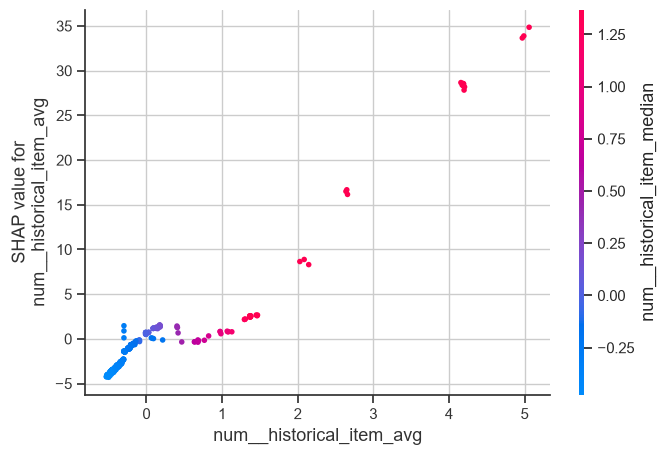

In [448]:
shap.dependence_plot(
    'num__historical_item_avg',
    rf_shap_values,
    X_rf_transformed,
    feature_names=rf_feature_names
)

In [449]:
# Compare actual prices, model predictions and historical features for the two highest-error items
item_diagnostics = model_data.loc[X_test.index].copy()
for model_name, preds in predictions.items():
    item_diagnostics[f"{model_name}_prediction"] = np.asarray(preds)
    item_diagnostics[f"{model_name}_error"] = (item_diagnostics[TARGET] - item_diagnostics[f"{model_name}_prediction"]).abs()
    item_diagnostics[f"{model_name}_percentage_error"] = np.where(item_diagnostics[TARGET].abs() > 0, item_diagnostics[f"{model_name}_error"] / item_diagnostics[TARGET].abs() * 100, np.nan)

selected_items = item_diagnostics.groupby("item_id")["Random Forest_error"].mean().nlargest(2).index
selected_diagnostics = item_diagnostics[item_diagnostics["item_id"].isin(selected_items)].copy()
diagnostic_columns = ["po_number", "order_date", "item_id", "vendor_id", "quantity_ordered", TARGET, "previous_paid_price", "previous_3_order_avg", "previous_3_order_median", "historical_item_avg", "historical_item_median", "historical_item_count", "historical_vendor_item_avg", "historical_vendor_item_median", "historical_vendor_item_count", "Baseline_prediction", "Ridge_prediction", "Random Forest_prediction", "XGBoost_prediction"]

display(selected_diagnostics[diagnostic_columns].sort_values(["item_id", "order_date"]).round(3))

,po_number,order_date,item_id,vendor_id,quantity_ordered,unit_price_paid,previous_paid_price,previous_3_order_avg,previous_3_order_median,historical_item_avg,historical_item_median,historical_item_count,historical_vendor_item_avg,historical_vendor_item_median,historical_vendor_item_count,Baseline_prediction,Ridge_prediction,Random Forest_prediction,XGBoost_prediction
1979,PO-100193,2026-06-12,ITM-0721,VEND-09,10,38.85,35.86,35.86,35.86,32.87,32.93,7.00,35.86,35.86,1.00,35.86,33.12,32.94,45.90
2168,PO-100689,2026-08-24,ITM-0721,VEND-10,6,34.42,33.65,32.90,32.93,33.62,32.97,8.00,32.52,32.93,5.00,32.52,33.74,31.70,36.55
1806,PO-100073,2026-03-19,ITM-0902,VEND-09,6,4.21,4.20,4.15,4.20,7.94,4.20,18.00,4.16,4.20,4.00,4.16,4.59,4.47,8.10
1900,PO-101435,2026-05-05,ITM-0902,VEND-09,6,4.43,4.21,4.20,4.20,7.74,4.20,19.00,4.17,4.20,5.00,4.17,4.67,4.56,8.15
2019,PO-101587,2026-07-01,ITM-0902,VEND-08,2,47.00,4.38,4.17,4.11,7.57,4.20,20.00,4.18,4.16,4.00,4.18,4.92,4.71,8.11
2153,PO-102314,2026-08-20,ITM-0902,VEND-11,2,4.26,4.15,3.93,3.83,9.45,4.20,21.00,3.93,3.83,3.00,3.93,5.12,4.22,3.90


In [ ]:
# Compare prediction performance across models for each selected item
item_performance = []
for item in selected_items:
    item_data = item_diagnostics[item_diagnostics["item_id"] == item]
    for model_name in predictions:
        item_performance.append({"Item": item, "Model": model_name, "Transactions": len(item_data), "Actual_Avg": item_data[TARGET].mean(), "Predicted_Avg": item_data[f"{model_name}_prediction"].mean(), "MAE": item_data[f"{model_name}_error"].mean(), "Max_Error": item_data[f"{model_name}_error"].max(), "MAPE": item_data[f"{model_name}_percentage_error"].mean()})

item_performance = pd.DataFrame(item_performance)

display(item_performance.round(3))

,Item,Model,Transactions,Actual_Avg,Predicted_Avg,MAE,Max_Error,MAPE
0,ITM-0902,Baseline,4,14.97,4.11,10.86,42.82,26.45
1,ITM-0902,Ridge,4,14.97,4.83,10.89,42.08,31.05
2,ITM-0902,Random Forest,4,14.97,4.49,10.68,42.29,25.01
3,ITM-0902,XGBoost,4,14.97,7.07,11.72,38.89,66.91
4,ITM-0721,Baseline,2,36.63,34.19,2.44,2.99,6.61
5,ITM-0721,Ridge,2,36.63,33.43,3.21,5.74,8.36
6,ITM-0721,Random Forest,2,36.63,32.32,4.32,5.91,11.57
7,ITM-0721,XGBoost,2,36.63,41.23,4.59,7.05,12.17
